<a href="https://colab.research.google.com/github/HARSHASRI33/Water-Potability-Prediction-Using-Random-Forest-Classification/blob/main/casestudy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score
)

# Download dataset
url = "https://raw.githubusercontent.com/TharunChougoni/water-potability-ml/master/data/water_potability.csv"
df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (3276, 10)


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB

Missing values:
ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64

Potabil

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
count,2785.000000,3276.000000,3276.000000,3276.000000,2495.000000,3276.000000,3276.000000,3114.000000,3276.000000,3276.000000
mean,7.080795,196.369496,22014.092526,7.122277,333.775777,426.205111,14.284970,66.396293,3.966786,0.390110
std,1.594320,32.879761,8768.570828,1.583085,41.416840,80.824064,3.308162,16.175008,0.780382,0.487849
min,0.000000,47.432000,320.942611,0.352000,129.000000,181.483754,2.200000,0.738000,1.450000,0.000000
25%,6.093092,176.850538,15666.690297,6.127421,307.699498,365.734414,12.065801,55.844536,3.439711,0.000000
50%,7.036752,196.967627,20927.833607,7.130299,333.073546,421.884968,14.218338,66.622485,3.955028,0.000000
75%,8.062066,216.667456,27332.762127,8.114887,359.950170,481.792304,16.557652,77.337473,4.500320,1.000000
max,14.000000,323.124000,61227.196008,13.127000,481.030642,753.342620,28.300000,124.000000,6.739000,1.000000


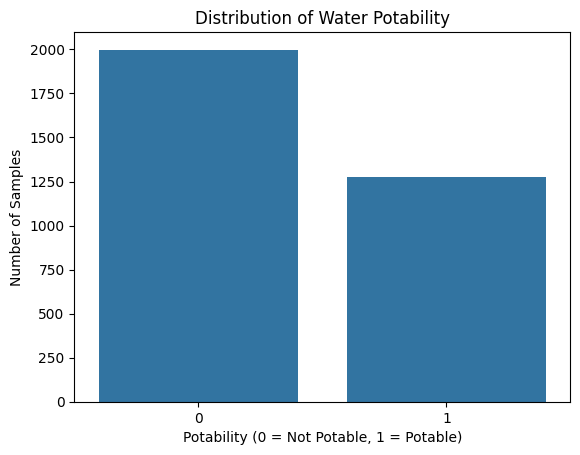

In [ ]:

print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nPotability distribution:")
print(df["Potability"].value_counts())

print("\nStatistical summary:")
display(df.describe())

# Plot class distribution
sns.countplot(x="Potability", data=df)
plt.title("Distribution of Water Potability")
plt.xlabel("Potability (0 = Not Potable, 1 = Potable)")
plt.ylabel("Number of Samples")
plt.show()

In [ ]:

X = df.drop("Potability", axis=1)
y = df["Potability"]

# Split: 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 2620
Testing samples: 656


In [ ]:

# Replace missing values using median of each feature
imputer = SimpleImputer(strategy="median")

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X.columns
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X.columns
)

print("Missing values after imputation:")
print(X_train.isnull().sum().sum())
print(X_test.isnull().sum().sum())

Missing values after imputation:
0
0


In [ ]:

model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [ ]:

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
auc = roc_auc_score(y_test, y_prob)

print("MODEL PERFORMANCE")
print("-----------------")
print(f"Accuracy  : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"ROC-AUC   : {auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Not Potable", "Potable"],
    zero_division=0
))

MODEL PERFORMANCE
-----------------
Accuracy  : 0.6707 (67.07%)
Precision : 0.6786
Recall    : 0.2969
F1 Score  : 0.4130
ROC-AUC   : 0.6625

Classification Report:
              precision    recall  f1-score   support

 Not Potable       0.67      0.91      0.77       400
     Potable       0.68      0.30      0.41       256

    accuracy                           0.67       656
   macro avg       0.67      0.60      0.59       656
weighted avg       0.67      0.67      0.63       656



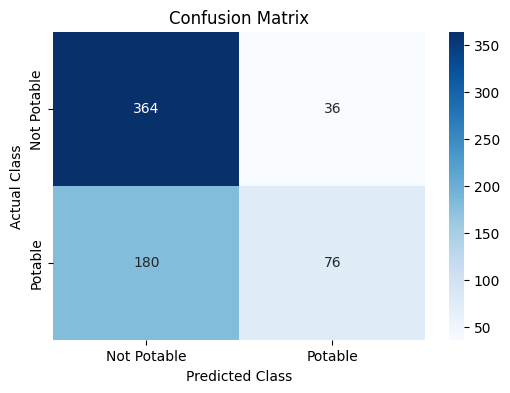

Confusion Matrix:
[[364  36]
 [180  76]]


In [ ]:

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Not Potable", "Potable"],
    yticklabels=["Not Potable", "Potable"]
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

print("Confusion Matrix:")
print(cm)

In [ ]:

cv_scores = cross_val_score(
    model, X_train, y_train,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

print("5-Fold Cross-Validation Scores:", np.round(cv_scores, 4))
print("Mean CV Accuracy:", round(cv_scores.mean(), 4))

5-Fold Cross-Validation Scores: [0.666  0.6698 0.6756 0.6679 0.6565]
Mean CV Accuracy: 0.6672


,Feature,Importance
0,ph,0.129315
4,Sulfate,0.126337
1,Hardness,0.118498
3,Chloramines,0.117692
2,Solids,0.113492
5,Conductivity,0.101356
8,Turbidity,0.099512
6,Organic_carbon,0.097155
7,Trihalomethanes,0.096642


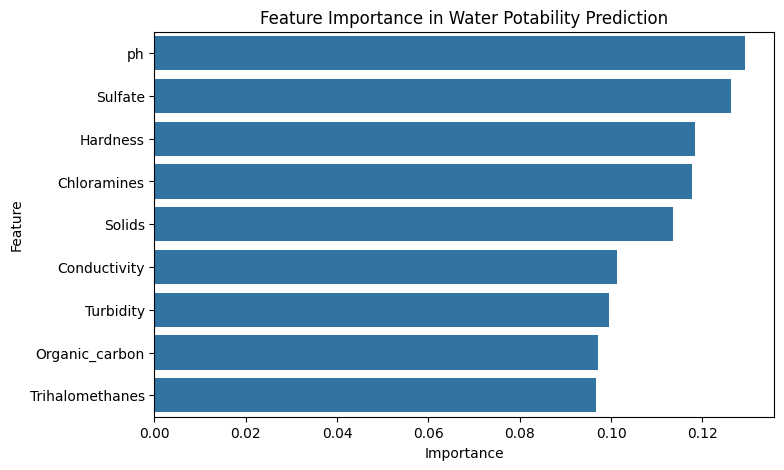

In [ ]:

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
}).sort_values(by="Importance", ascending=False)

display(importance)

plt.figure(figsize=(8, 5))
sns.barplot(data=importance, x="Importance", y="Feature")
plt.title("Feature Importance in Water Potability Prediction")
plt.show()

In [ ]:

results = X_test.copy()
results["Actual"] = y_test.values
results["Predicted"] = y_pred
results["Correct"] = results["Actual"] == results["Predicted"]

correct_rows = results[results["Correct"] == True]
incorrect_rows = results[results["Correct"] == False]

print("CORRECT PREDICTION")
if len(correct_rows) > 0:
    display(correct_rows.head(1))
else:
    print("No correct prediction found.")

print("INCORRECT PREDICTION")
if len(incorrect_rows) > 0:
    display(incorrect_rows.head(1))
else:
    print("No incorrect prediction found in this test run.")

CORRECT PREDICTION


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Actual,Predicted,Correct
1,6.172517,187.787017,10498.635154,7.722561,322.521035,467.090425,21.233978,68.163642,4.129985,0,0,True


INCORRECT PREDICTION


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Actual,Predicted,Correct
0,7.035037,188.743562,19037.462638,6.034236,333.073546,388.065857,15.149068,78.499418,2.723651,1,0,False


In [ ]:

# Example measurements for demonstration only.
# Replace these values with actual laboratory measurements.
new_sample = pd.DataFrame([{
    "ph": 7.0,
    "Hardness": 180.0,
    "Solids": 15000.0,
    "Chloramines": 7.0,
    "Sulfate": 250.0,
    "Conductivity": 400.0,
    "Organic_carbon": 12.0,
    "Trihalomethanes": 60.0,
    "Turbidity": 3.5
}])

new_sample = new_sample[X.columns]
new_sample_clean = imputer.transform(new_sample)

prediction = model.predict(new_sample_clean)[0]
probability = model.predict_proba(new_sample_clean)[0]

print("Predicted class:", prediction)
print("Probability of non-potable:", round(probability[0] * 100, 2), "%")
print("Probability of potable:", round(probability[1] * 100, 2), "%")

if prediction == 1:
    print("Model result: POTABLE")
else:
    print("Model result: NOT POTABLE")

Predicted class: 1
Probability of non-potable: 36.5 %
Probability of potable: 63.5 %
Model result: POTABLE


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
